In [1]:
import warnings

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import auc, confusion_matrix, f1_score, recall_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import shuffle as sk_shuffle
from toolbox import (
    Masking,
    augment_patient_and_cat_specific,
    find_all_indices,
    hot_coding,
    visualize_Category_hist,
)
from toolbox.loading import load_data

In [2]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
# set prints off
mask.prints = False

__IIVV-results from statistical evaluation__

## Contents

- SNR Data augmentation tuning
- Model tuning
    - SVM tuning
    - RF tuning
    - LR tuning



**Data loading**

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -5.841877056904085e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"MC"`

In [4]:
# class_task = "healthy_vs_cancer"
 class_task = "cancer_vs_lr_hr"
# class_task = "MC"

data_augmentation = False

Healthy vs. cancer

Healthy: 90 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{'Cancer': [1, 0], 'Healthy': [0, 1]}


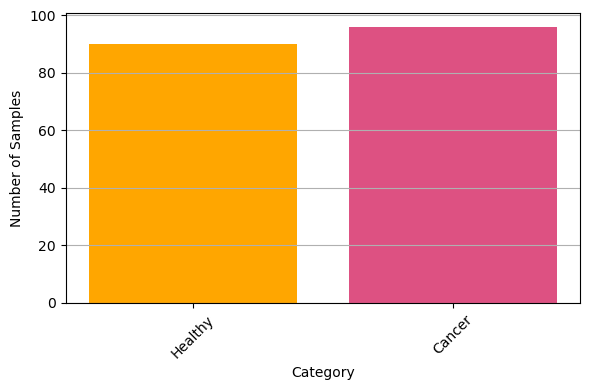


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(186, 31, 7728) (186, 2) (186,)


In [5]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    # for SVD kernel boundary
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        1: "#003F5C",  # healthy
        0: "#FFA600",  # cancer
    }
    cp_l = {
        1: "healthy",  # healthy
        0: "cancer",  # cancer
    }
    visualize_Category_hist(labels)

elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        1: "#DD5182",  # non-cancer
        0: "#FFA600",  # cancer
    }
    cp_l = {
        1: "healthy",  # non-cancer
        0: "cancer",  # cancer
    }
    visualize_Category_hist(labels)

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "High-grade dysplasia", "Non-malignant"],
        split=False,
    )
    labels = labels_MC[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        0: "#58508D",  # Non-malignant
        1: "#FFA600",  # Cancer
        2: "#003F5C",  # Healthy
        3: "#FF6361",  # High-grade dysplasia
    }
    cp_l = {
        0: "Non-malignant",
        1: "Cancer",
        2: "Healthy",
        3: "High-grade dysplasia",
    }
    aug_dict = {
        "High-grade dysplasia": 70,
        "Non-malignant": 70,
    }

Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)

if class_task == "MC" and data_augmentation:
    print("\n\t\tBefore augmentation")
    visualize_Category_hist(labels)
    X, Y_labels, labels, Case = augment_patient_and_cat_specific(
        X, Y_labels, labels, Case, aug_dict
    )
    print("\n\t\tAfter augmentation")
    visualize_Category_hist(labels)

# Model tuning

**Tuning using `GridSearch()` with `GroupKFold()` train/test data split**

- SVM tuning
- RF tuning
- LR tuning

In [6]:
n_folds = 5  # number of iterations inside each LPOCV
output_prints = False

# load frequency selection
tmp = np.load(f"results/freq_fold_results_{class_task}.npz", allow_pickle=True)
top_freqs_baseline = tmp["top_freqs_baseline"]
print(f"{top_freqs_baseline=}")
# Top frequency groups for Task 1: 5,6,8,7, Task 2: 4,2,29,27, Task 3: 23,28,24,27

if class_task == "healthy_vs_cancer":
    print("Task 1: 6,14,5,7")
    Freq_sel = {
        "Top 6": top_freqs_baseline[:6],
        "Top 14": top_freqs_baseline[:14],
        "Top 5": top_freqs_baseline[:5],       
        "Top 7": top_freqs_baseline[:7],
        
        # "All": top_freqs_baseline,  # np.arange(31),
    }
elif class_task == "cancer_vs_hbd":
    print("Task 2: 3,4,2,5")
    Freq_sel = {
        "Top 3": top_freqs_baseline[:3],
        "Top 4": top_freqs_baseline[:4],
        "Top 2": top_freqs_baseline[:2],
        "Top 5": top_freqs_baseline[:5],
        # "All": top_freqs_baseline,  # np.arange(31),
    }
elif class_task == "cancer_vs_lr_hr":
    print("Task 2: 4,2,29,17")
    Freq_sel = {
        "Top 4": top_freqs_baseline[:4],
        "Top 2": top_freqs_baseline[:2],
        "Top 29": top_freqs_baseline[:29],
        "Top 17": top_freqs_baseline[:17],
        # "All": top_freqs_baseline,  # np.arange(31),
    }
elif class_task == "hr_vs_lr":
    print("Task 2: 30,3,27,28")
    Freq_sel = {
        "Top 30": top_freqs_baseline[:30],
        "Top 3": top_freqs_baseline[:3],
        "Top 27": top_freqs_baseline[:27],
        "Top 28": top_freqs_baseline[:28],
        # "All": top_freqs_baseline,  # np.arange(31),
    }
if class_task == "MC":
    print("Task 3: 13,19,20,18")
    Freq_sel = {
        "Top 13": top_freqs_baseline[:13],
        "Top 19": top_freqs_baseline[:19],
        "Top 20": top_freqs_baseline[20],
        "Top 18": top_freqs_baseline[:18],
        # "All": top_freqs_baseline,  # np.arange(31),
    }

# load masking selection
tmp = np.load(f"results/Top_IIVV_masks_{class_task}.npz", allow_pickle=True)
Mask_ranks = tmp["Mask_ranks"][:4]

Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}
Mask_sel = {k: v for k, v in Mask_sel.items() if k in Mask_ranks}
print(Mask_sel)

top_freqs_baseline=array([30,  0, 27, 12, 29,  8, 28, 13, 16, 26, 10, 11, 25, 17,  1, 24, 20,
       15, 21, 19, 23, 22,  2, 18,  7, 14,  3,  4,  5,  9,  6],
      dtype=int64)
Task 1: 5,6,8,7


ModuleNotFoundError: No module named 'numpy._core'

In [7]:
# Z-thresholding selection 

# load in average impedances 
avg_Z_fp = np.load('Avg_Zs.npy')

if class_task == "healthy_vs_cancer":
    print("Task 1 Z-threshold: 386")
    z_thresh = 386 
elif class_task == 'cancer_vs_hbd':
    print("Task 2 Z-threshold: 423")
    z_thresh = 423 
elif class_task == 'MC':
    print("Task 3 Z-threshold: 592")
    z_thresh = 592

Msel = f"z_threshold: {z_thresh}"

Task 1 Z-threshold: 386


## SVM tuning

In [ ]:
stats_df = []
use_model = "SVM"

param_grid = {
    "kernel": ["linear", "poly", "rbf", "sigmoid"],
    "C": np.logspace(-3, 3, 7, dtype=float),  # [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
for Fsel in Freq_sel.keys():
    for random_state in range(10):

        cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)
        """
        for fold, (train_idx, test_idx) in enumerate(cv.split(X_tmp, Y_labels, groups=Case), 1):
            print(f"Fold {fold}")
            print("  Train groups:", Case[train_idx])
            print("  Test groups :", Case[test_idx])
            print("  Train idx   :", train_idx)
            print("  Test idx    :", test_idx)
            print()
        """
        m = SVC(probability=True, random_state=random_state)

        grid_search = GridSearchCV(
            estimator=m,
            param_grid=param_grid,
            cv=cv,
            scoring="roc_auc_ovr",
            n_jobs=80,
        )

        # select freq and IIVV and shape data
        X_tmp = X[:, Freq_sel[Fsel], :]
              
        # Select columns/patterns for this threshold
        above_threshold = avg_Z_fp[0,:] <= z_thresh
        X_tmp = X_tmp[:, :, above_threshold]
        X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

        grid_search.fit(X_tmp, Y_labels, groups=Case)

        best_params = grid_search.best_params_
        best_score = grid_search.best_score_

        if output_prints:
            print(f"\nRandom_state{random_state}")
            print("Best parameters:", best_params)
            print("Best ROC AUC:", best_score)

        df_row = {
            "Architecture": use_model,
            "Fsel": Fsel,
            "Msel": Msel,
            "n_params": X_tmp.shape[1],
            "Random_state": random_state,
            "val AUC": best_score,
        }
        df_row.update(best_params)
        stats_df.append(df_row)

df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_SVM_z_thresh_{class_task}.csv", index=False)

Exception in thread ExecutorManagerThread:
Traceback (most recent call last):
  File "C:\Users\f005cgg\AppData\Local\anaconda3\envs\machine_learning\Lib\threading.py", line 1038, in _bootstrap_inner
    self.run()
  File "C:\Users\f005cgg\AppData\Local\anaconda3\envs\machine_learning\Lib\site-packages\joblib\externals\loky\process_executor.py", line 557, in run
    result_item, is_broken, bpe = self.wait_result_broken_or_wakeup()
                                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\f005cgg\AppData\Local\anaconda3\envs\machine_learning\Lib\site-packages\joblib\externals\loky\process_executor.py", line 611, in wait_result_broken_or_wakeup
    ready = wait(readers + worker_sentinels)
            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\f005cgg\AppData\Local\anaconda3\envs\machine_learning\Lib\multiprocessing\connection.py", line 878, in wait
    ready_handles = _exhaustive_wait(waithandle_to_obj.keys(), timeout)
                    ^^^^^^^^^^^^^^

In [20]:
param_grid = {
    "kernel": ["linear", "poly", "rbf", "sigmoid"],
    "C": np.logspace(-3, 3, 7, dtype=float),  # [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_SVM_z_thresh_{class_task}.csv")

In [21]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

  hpt_combinations   val AUC
0     linear_0.001  0.901352
1      linear_0.01  0.899914
2       linear_0.1  0.908242
3        poly_0.01  0.902310
4         poly_0.1  0.899432
5         poly_1.0  0.912754
6          rbf_0.1  0.897542
7          rbf_1.0  0.902525
8         rbf_10.0  0.907243
9      sigmoid_0.1  0.892857

Column: hpt_combinations
hpt_combinations
linear_0.001    39
rbf_10.0        34
rbf_1.0         26
poly_0.1        25
rbf_0.1         10
linear_0.01      9
poly_0.01        5
poly_1.0         5
linear_0.1       4
sigmoid_0.1      3
Name: count, dtype: int64


[Plot-svm-kernels](https://scikit-learn.org/stable/auto_examples/svm/plot_svm_kernels.html#rbf-kernel)

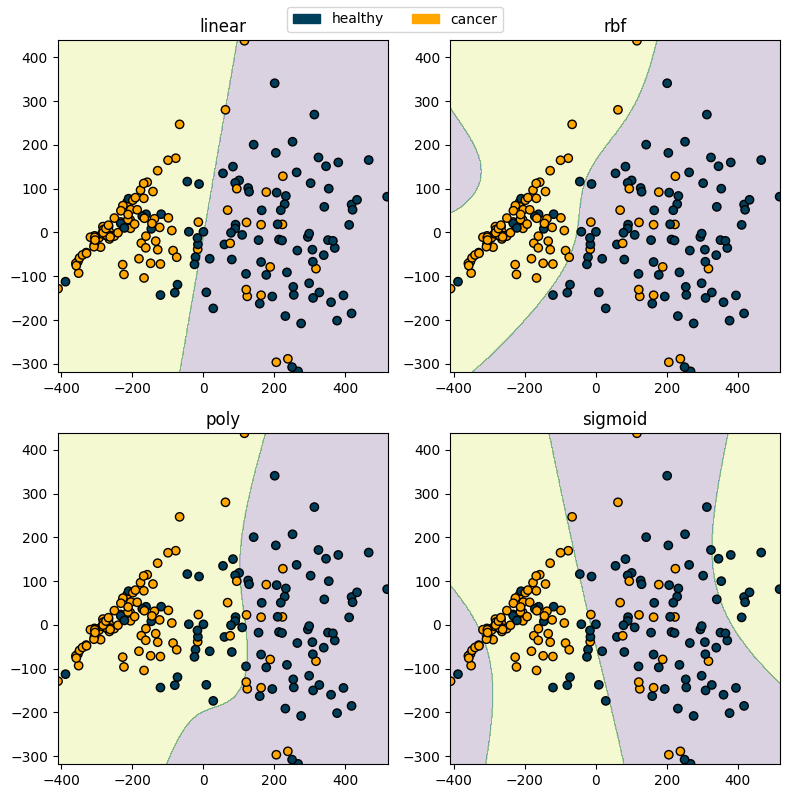

In [10]:
C_val = 10

X_flat = X.reshape(X.shape[0], -1)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_flat)

kernels = ["linear", "rbf", "poly", "sigmoid"]
colors = [cp[label] for label in Y_labels]
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.ravel()
for i, kernel in enumerate(kernels):
    clf = SVC(kernel=kernel, C=10)
    clf.fit(X_2d, Y_labels)

    x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
    y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axes[i].contourf(xx, yy, -1 * Z, alpha=0.2)
    scatter = axes[i].scatter(X_2d[:, 0], X_2d[:, 1], c=colors, edgecolor="k")
    axes[i].set_title(f"{kernel}")
    legend_handles = [mpatches.Patch(color=cp[k], label=cp_l[k]) for k in cp.keys()]
fig.legend(handles=legend_handles, loc="upper center", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    f"results/SVM_kernels_z_thresh_{class_task}_{C_val}.pdf",
    bbox_inches="tight",
)
plt.show()

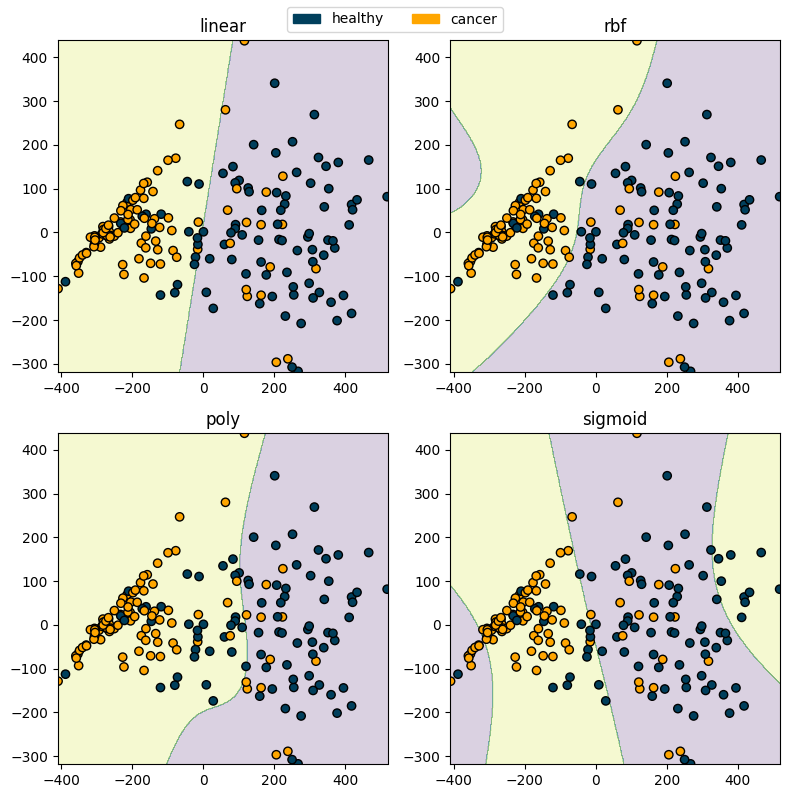

In [11]:
C_val = 1000

X_flat = X.reshape(X.shape[0], -1)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_flat)

kernels = ["linear", "rbf", "poly", "sigmoid"]
colors = [cp[label] for label in Y_labels]
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.ravel()
for i, kernel in enumerate(kernels):
    clf = SVC(kernel=kernel, C=10)
    clf.fit(X_2d, Y_labels)

    x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
    y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axes[i].contourf(xx, yy, -1 * Z, alpha=0.2)
    scatter = axes[i].scatter(X_2d[:, 0], X_2d[:, 1], c=colors, edgecolor="k")
    axes[i].set_title(f"{kernel}")
    legend_handles = [mpatches.Patch(color=cp[k], label=cp_l[k]) for k in cp.keys()]
fig.legend(handles=legend_handles, loc="upper center", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    f"results/SVM_kernels_z_thresh_{class_task}_{C_val}.pdf",
    bbox_inches="tight",
)
plt.show()

## RF tuning

In [12]:
stats_df = []
use_model = "RF"

param_grid = {
    "n_estimators": [100, 300, 500, 800],
    "max_depth": [510, 20, None],
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}
for Fsel in Freq_sel.keys():
    for random_state in range(10):
        cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)

        m = RandomForestClassifier(random_state=random_state)

        grid_search = GridSearchCV(
            estimator=m,
            param_grid=param_grid,
            cv=cv,
            scoring="roc_auc_ovr",
            n_jobs=80,
        )

        # select freq and IIVV and shape data
        X_tmp = X[:, Freq_sel[Fsel], :]
        
        # Select columns/patterns for this threshold
        above_threshold = avg_Z_fp[0,:] <= z_thresh
        X_tmp = X_tmp[:, :, above_threshold]
        X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

        grid_search.fit(X_tmp, Y_labels, groups=Case)

        best_params = grid_search.best_params_
        best_score = grid_search.best_score_

        if output_prints:
            print(f"\nRandom_state{random_state}")
            print("Best parameters:", best_params)
            print("Best ROC AUC:", best_score)

        df_row = {
            "Architecture": use_model,
            "Fsel": Fsel,
            "Msel": Msel,
            "n_params": X_tmp.shape[1],
            "Random_state": random_state,
            "val AUC": best_score,
        }
        df_row.update(best_params)
        stats_df.append(df_row)
df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_RF_z_thresh_{class_task}.csv", index=False)

In [22]:
param_grid = {
    "n_estimators": [100, 300, 500, 800],
    "max_depth": [510, 20, None],
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_RF_z_thresh_{class_task}.csv")

In [23]:
df

,Architecture,Fsel,Msel,n_params,Random_state,val AUC,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
0,RF,Top 5,Med. adj.,1935,0,0.914749,510,log2,1,2,800
1,RF,Top 5,Med. adj.,1935,1,0.906752,510,sqrt,1,2,300
2,RF,Top 5,Med. adj.,1935,2,0.912833,510,log2,4,2,100
3,RF,Top 5,Med. adj.,1935,3,0.911563,510,log2,1,5,500
4,RF,Top 5,Med. adj.,1935,4,0.922350,510,sqrt,4,10,100
...,...,...,...,...,...,...,...,...,...,...,...
155,RF,Top 7,Opp. medium,1848,5,0.903328,510,log2,1,5,100
156,RF,Top 7,Opp. medium,1848,6,0.918277,510,log2,2,10,300
157,RF,Top 7,Opp. medium,1848,7,0.908080,510,sqrt,4,10,300
158,RF,Top 7,Opp. medium,1848,8,0.919938,510,sqrt,2,2,100


In [24]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

     hpt_combinations   val AUC
0   100_510_log2_10_1  0.915700
1   100_510_log2_10_2  0.911843
2   100_510_log2_10_4  0.908267
3    100_510_log2_2_1  0.909490
4    100_510_log2_2_2  0.915603
5    100_510_log2_2_4  0.912377
6    100_510_log2_5_1  0.912697
7    100_510_log2_5_2  0.917199
8   100_510_sqrt_10_1  0.907679
9   100_510_sqrt_10_2  0.917610
10  100_510_sqrt_10_4  0.911350
11   100_510_sqrt_2_2  0.914067
12   100_510_sqrt_2_4  0.908760
13   100_510_sqrt_5_1  0.918963
14   100_510_sqrt_5_2  0.899121
15  300_510_log2_10_1  0.914672
16  300_510_log2_10_2  0.912712
17  300_510_log2_10_4  0.905477
18   300_510_log2_2_1  0.917010
19   300_510_log2_2_4  0.911951
20   300_510_log2_5_1  0.923567
21   300_510_log2_5_2  0.920915
22  300_510_sqrt_10_1  0.906139
23  300_510_sqrt_10_2  0.913529
24  300_510_sqrt_10_4  0.911231
25   300_510_sqrt_2_1  0.913286
26   300_510_sqrt_2_4  0.903821
27   300_510_sqrt_5_1  0.912922
28   300_510_sqrt_5_2  0.911693
29  500_510_log2_10_1  0.917133
30  500_

In [16]:
df

,Architecture,Fsel,Msel,n_params,Random_state,val AUC,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators,hpt_combinations
0,RF,Top 5,Med. adj.,1935,0,0.914749,510,log2,1,2,800,800_510_log2_2_1
1,RF,Top 5,Med. adj.,1935,1,0.906752,510,sqrt,1,2,300,300_510_sqrt_2_1
2,RF,Top 5,Med. adj.,1935,2,0.912833,510,log2,4,2,100,100_510_log2_2_4
3,RF,Top 5,Med. adj.,1935,3,0.911563,510,log2,1,5,500,500_510_log2_5_1
4,RF,Top 5,Med. adj.,1935,4,0.922350,510,sqrt,4,10,100,100_510_sqrt_10_4
...,...,...,...,...,...,...,...,...,...,...,...,...
155,RF,Top 7,Opp. medium,1848,5,0.903328,510,log2,1,5,100,100_510_log2_5_1
156,RF,Top 7,Opp. medium,1848,6,0.918277,510,log2,2,10,300,300_510_log2_10_2
157,RF,Top 7,Opp. medium,1848,7,0.908080,510,sqrt,4,10,300,300_510_sqrt_10_4
158,RF,Top 7,Opp. medium,1848,8,0.919938,510,sqrt,2,2,100,100_510_sqrt_2_2


### LR tuning

In [17]:
stats_df = []
use_model = "LR"

param_grid = {
    # "penalty": ["l1", "l2", "elasticnet", None],
    "C": [0.01, 0.1, 1, 10, 100],
    "max_iter": [100, 1000, 10_000],
    # "solver": ["saga"],
}

for Fsel in Freq_sel.keys():
    for random_state in range(10):
        cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)

        m = LogisticRegression(random_state=random_state)

        grid_search = GridSearchCV(
            estimator=m,
            param_grid=param_grid,
            cv=cv,
            scoring="roc_auc_ovr",
            n_jobs=80,
        )

        # select freq and IIVV and shape data
        X_tmp = X[:, Freq_sel[Fsel], :]

        # Select columns/patterns for this threshold
        above_threshold = avg_Z_fp[0,:] <= z_thresh
        X_tmp = X_tmp[:, :, above_threshold]
        X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

        grid_search.fit(X_tmp, Y_labels, groups=Case)

        best_params = grid_search.best_params_
        best_score = grid_search.best_score_

        if output_prints:
            print(f"\nRandom_state{random_state}")
            print("Best parameters:", best_params)
            print("Best ROC AUC:", best_score)

        df_row = {
            "Architecture": use_model,
            "Fsel": Fsel,
            "Msel": Msel,
            "n_params": X_tmp.shape[1],
            "Random_state": random_state,
            "val AUC": best_score,
        }
        df_row.update(best_params)
        stats_df.append(df_row)

df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_LR_z_thresh_{class_task}.csv", index=False)

In [25]:
param_grid = {
    # "penalty": ["l1", "l2", "elasticnet", None],
    "C": [0.01, 0.1, 1, 10, 100],
    "max_iter": [100, 1000, 10_000],
    # "solver": ["saga"],
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_LR_z_thresh_{class_task}.csv")

In [26]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

  hpt_combinations   val AUC
0         0.01_100  0.889046
1          0.1_100  0.903550
2         0.1_1000  0.906194

Column: hpt_combinations
hpt_combinations
0.01_100    99
0.1_100     58
0.1_1000     3
Name: count, dtype: int64


___